<a href="https://colab.research.google.com/github/RishitJha/MFCAD-/blob/main/MFCAD%2B%2B_dataset_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#chunk 1
#1
# Mount Google Drive so Colab can see the project folder (accept the popup)
from google.colab import drive
drive.mount('/content/drive')

# Make our helper file importable, then import it
import sys
sys.path.append("/content/drive/MyDrive/mfcad_project")
import helpers

# Path of the zip that lives safely in Drive
ZIP_PATH = "/content/drive/MyDrive/mfcad_project/data/MFCAD_dataset.zip"

# Unzip ONLY the h5 graph files (we do not need the 59,665 STEP files for this phase).
# If the validation h5 file already exists, skip the unzip.
!test -f "/content/mfcad/MFCAD++_dataset/hierarchical_graphs/val_MFCAD++.h5" && echo "h5 files already present." || unzip -q -o "{ZIP_PATH}" "*hierarchical_graphs*" -d /content/mfcad

# List the h5 files with their sizes to confirm they are there
!ls -la "/content/mfcad/MFCAD++_dataset/hierarchical_graphs"

# Show which chunks are already finished
helpers.show_progress()

Mounted at /content/drive
total 1653516
drwxrwxrwx 2 root root       4096 Jan 19  2022 .
drwxr-xr-x 3 root root       4096 Nov 25 06:46 ..
-rwxrwxrwx 1 root root  254891510 Sep  8  2021 test_MFCAD++.h5
-rwxrwxrwx 1 root root 1185273297 Sep  1  2021 training_MFCAD++.h5
-rwxrwxrwx 1 root root  253007219 Sep  1  2021 val_MFCAD++.h5
chunk0_setup: finished 2026-11-23 11:07:56  folders and helpers created
chunk1_load_data: finished 2026-11-23 11:45:40  uploaded, unzipped, inspected
chunk2_understand_data: finished 2026-11-23 12:01:15  h5 structure and val class counts
chunk2b_verify_h5: finished 2026-11-23 12:22:47  val h5 consistency checks
chunk3_cache: finished 2026-11-23 13:55:57  face-level caches for train, val and test
chunk3b_face_model_fix: finished 2026-11-23 14:08:38  face_model rebuilt from idx in all caches
chunk4_mlp: finished 2026-11-24 04:48:22  MLP baseline trained and evaluated on val
chunk5_gnn: finished 2026-11-24 08:09:24  neighbour-aware GNN trained and evaluated on val

In [ ]:
#chunk 1
#2
import h5py            # reads the .h5 files
import numpy as np     # array maths
import time            # to time each split

H5_DIR = "/content/mfcad/MFCAD++_dataset/hierarchical_graphs"   # where the h5 files are
SPLITS = {"train": "training_MFCAD++.h5", "val": "val_MFCAD++.h5", "test": "test_MFCAD++.h5"}
MATS = ["A_1", "A_2", "A_3", "E_1", "E_2", "E_3"]   # all the sparse matrices we will use

report = {}   # everything we find goes here and is saved to Drive at the end

for split, fname in SPLITS.items():
    t0 = time.time()                                   # start the timer for this split
    n_batches = 0                                      # how many h5 batches
    not_one = {m: 0 for m in MATS}                     # count of matrix values that are NOT exactly 1
    vmin = {m: np.inf for m in MATS}                   # smallest value seen per matrix
    vmax = {m: -np.inf for m in MATS}                  # largest value seen per matrix
    v1_min, v1_max = np.full(5, np.inf), np.full(5, -np.inf)   # range of each V_1 column
    v2_min, v2_max = np.full(4, np.inf), np.full(4, -np.inf)   # range of each V_2 column
    max_dev = 0.0                                      # how far surface type*11 is from a whole number
    shape_bad = 0                                      # batches whose matrix shapes look wrong
    first_bad = None                                   # the shapes of the first bad batch, to look at
    with h5py.File(f"{H5_DIR}/{fname}", "r") as f:
        first_keys = list(f.keys())[:5]                # the order h5py gives us the batches in
        for name in f.keys():                          # go through every batch
            b = f[name]
            n_batches += 1
            # 1) matrix values: are they all exactly 1?
            for m in MATS:
                vals = b[f"{m}_values"][:]             # the stored edge values
                if vals.size == 0:                     # no edges of this kind in this batch
                    continue
                not_one[m] += int((vals != 1).sum())   # count values different from 1
                vmin[m] = min(vmin[m], float(vals.min()))
                vmax[m] = max(vmax[m], float(vals.max()))
            # 2) raw feature ranges
            v1 = b["V_1"][:]                           # face features (faces, 5)
            v2 = b["V_2"][:]                           # facet features (facets, 4)
            v1_min = np.minimum(v1_min, v1.min(axis=0)); v1_max = np.maximum(v1_max, v1.max(axis=0))
            v2_min = np.minimum(v2_min, v2.min(axis=0)); v2_max = np.maximum(v2_max, v2.max(axis=0))
            code = v1[:, 4] * 11                       # surface type scaled back to a code
            max_dev = max(max_dev, float(np.abs(code - np.rint(code)).max()))
            # 3) matrix shapes must agree with the number of faces and facets
            n_faces, n_facets = v1.shape[0], v2.shape[0]
            s = {m: tuple(int(v) for v in b[f"{m}_shape"][:]) for m in MATS}
            ok = (s["A_1"] == (n_faces, n_faces) and s["A_2"] == (n_facets, n_facets)
                  and s["A_3"] == (n_facets, n_faces)
                  and s["E_1"] == s["A_1"] and s["E_2"] == s["A_1"] and s["E_3"] == s["A_1"])
            if not ok:
                shape_bad += 1
                if first_bad is None:
                    first_bad = {"batch": name, "faces": n_faces, "facets": n_facets, "shapes": s}
    report[split] = {
        "batches": n_batches, "first_keys": first_keys,
        "values_not_equal_1": not_one,
        "value_min": {m: vmin[m] for m in MATS}, "value_max": {m: vmax[m] for m in MATS},
        "V1_min": v1_min.tolist(), "V1_max": v1_max.tolist(),
        "V2_min": v2_min.tolist(), "V2_max": v2_max.tolist(),
        "surface_code_max_deviation": max_dev,
        "batches_with_bad_shapes": shape_bad, "first_bad_shapes": first_bad,
    }
    r = report[split]                                  # print a readable summary
    print(f"\n===== {split}: {n_batches} batches ({time.time() - t0:.0f}s) =====")
    print("first keys in file order:", first_keys)
    print("matrix values NOT equal to 1:", r["values_not_equal_1"])
    print("matrix value range (min, max):", {m: (vmin[m], vmax[m]) for m in MATS})
    print("V_1 min:", np.round(v1_min, 4).tolist())
    print("V_1 max:", np.round(v1_max, 4).tolist())
    print("V_2 min:", np.round(v2_min, 4).tolist())
    print("V_2 max:", np.round(v2_max, 4).tolist())
    print("surface code max deviation from whole number:", round(max_dev, 6))
    print("batches with bad matrix shapes:", shape_bad, "| first bad:", first_bad)

# Save the findings to Drive and mark this step finished
helpers.save_json(report, "notes", "phase1a_raw_check.json")
helpers.mark_done("phase1a_raw_check", note="raw value ranges, matrix values and shapes checked")
helpers.show_progress()


===== train: 1473 batches (8s) =====
first keys in file order: ['0', '1', '10', '100', '1000']
matrix values NOT equal to 1: {'A_1': 0, 'A_2': 0, 'A_3': 0, 'E_1': 0, 'E_2': 0, 'E_3': 0}
matrix value range (min, max): {'A_1': (1.0, 1.0), 'A_2': (1.0, 1.0), 'A_3': (1.0, 1.0), 'E_1': (1.0, 1.0), 'E_2': (1.0, 1.0), 'E_3': (1.0, 1.0)}
V_1 min: [0.0, 0.0, 0.0, 0.0, 0.0909]
V_1 max: [1.0, 1.0, 1.0, 1.0, 0.7273]
V_2 min: [0.0, 0.0, 0.0, -10906.542]
V_2 max: [1.0, 1.0, 1.0, 10906.542]
surface code max deviation from whole number: 7e-06
batches with bad matrix shapes: 0 | first bad: None

===== val: 312 batches (2s) =====
first keys in file order: ['0', '1', '10', '100', '101']
matrix values NOT equal to 1: {'A_1': 0, 'A_2': 0, 'A_3': 0, 'E_1': 0, 'E_2': 0, 'E_3': 0}
matrix value range (min, max): {'A_1': (1.0, 1.0), 'A_2': (1.0, 1.0), 'A_3': (1.0, 1.0), 'E_1': (1.0, 1.0), 'E_2': (1.0, 1.0), 'E_3': (1.0, 1.0)}
V_1 min: [0.0, 0.0, 0.0, 0.0, 0.0909]
V_1 max: [1.0, 1.0, 1.0, 1.0, 0.7273]
V_2 min: 

In [ ]:
#chunk 1
#3
%%writefile /content/drive/MyDrive/mfcad_project/raw_builder.py
# raw_builder.py
# Rebuilds the face + mesh data from the h5 files WITHOUT changing any numbers:
# raw V_1 (5 channels) and raw V_2 (4 channels), as the paper's code uses them.

import os                      # file paths and safe file replacing
import h5py                    # reads the .h5 files
import numpy as np             # array maths
import torch                   # we save the result with torch.save

N_CLASSES = 25                 # labels 0..24 (24 = Stock)
MATS = ["A_1", "A_2", "A_3", "E_1", "E_2", "E_3"]   # the sparse matrices we keep


def read_pairs(b, name):       # read the (row, column) pairs of one sparse matrix
    a = np.asarray(b[f"{name}_idx"][:]).reshape(-1, 2)    # shape (E, 2); also works when E = 0
    return torch.from_numpy(np.ascontiguousarray(a.T.astype(np.int32)))   # shape (2, E): row 0 = rows, row 1 = columns


def check_range(t, limit, what):   # every index must lie inside 0 .. limit-1
    if t.numel() and (int(t.min()) < 0 or int(t.max()) >= limit):   # only test non-empty tensors
        raise ValueError(f"{what}: index outside 0..{limit - 1}")   # stop loudly if something is wrong


def build_split(h5_path, out_path):    # convert one h5 split and save it
    batches = []                                         # one dictionary per h5 batch
    class_counts = np.zeros(N_CLASSES, dtype=np.int64)   # faces per class
    tot = {"models": 0, "faces": 0, "facets": 0}         # running totals
    edge_sum_mismatch = 0                                # batches where E_1+E_2+E_3 != A_1 in size
    d_min, d_max = np.inf, -np.inf                       # range of the raw V_2 column 3
    with h5py.File(h5_path, "r") as f:                   # open the h5 file for reading
        names = list(f.keys())                           # batch names in FILE order (like the authors' code)
        for k, name in enumerate(names):                 # go through every batch
            b = f[name]                                  # this batch
            v1 = b["V_1"][:].astype(np.float32)          # raw face features (faces, 5)
            v2 = b["V_2"][:].astype(np.float32)          # raw facet features (facets, 4)
            lab = b["labels"][:]                         # face labels (stored as floats)
            idx = b["idx"][:].astype(np.int64)           # last face / last facet of every model
            ids = [x.decode() for x in b["CAD_model"][:]]   # model ids in this batch
            nf, nm = v1.shape[0], v2.shape[0]            # number of faces and of facets
            # ---- safety checks: stop loudly if the file is not shaped as expected ----
            if v1.shape[1] != 5 or v2.shape[1] != 4:     # feature widths must be 5 and 4
                raise ValueError(f"batch {name}: unexpected feature widths")
            if len(lab) != nf or len(ids) != len(idx):   # one label per face, one idx row per model
                raise ValueError(f"batch {name}: label or id count mismatch")
            if (not np.all(lab == np.rint(lab))) or lab.min() < 0 or lab.max() >= N_CLASSES:   # labels = whole numbers 0..24
                raise ValueError(f"batch {name}: bad labels")
            if int(idx[-1, 0]) != nf - 1 or int(idx[-1, 1]) != nm - 1:   # last model must end at the last face / facet
                raise ValueError(f"batch {name}: idx does not end at the last face/facet")
            m = {n: read_pairs(b, n) for n in MATS}      # all sparse matrices as (2, E) tensors
            for n in ("A_1", "E_1", "E_2", "E_3"):       # face-level matrices: indices < number of faces
                check_range(m[n], nf, f"{name}/{n}")
            check_range(m["A_2"], nm, f"{name}/A_2")     # facet-level matrix: indices < number of facets
            check_range(m["A_3"][0], nm, f"{name}/A_3 rows")      # A_3 rows are facets
            check_range(m["A_3"][1], nf, f"{name}/A_3 columns")   # A_3 columns are faces
            if m["A_3"].shape[1] != nm or np.unique(m["A_3"][0].numpy()).size != nm:   # each facet exactly once
                raise ValueError(f"batch {name}: each facet must appear exactly once in A_3")
            y = np.rint(lab).astype(np.int64)            # labels as whole numbers
            class_counts += np.bincount(y, minlength=N_CLASSES)   # count faces per class
            edge_sum_mismatch += int(m["E_1"].shape[1] + m["E_2"].shape[1] + m["E_3"].shape[1] != m["A_1"].shape[1])
            d_min, d_max = min(d_min, float(v2[:, 3].min())), max(d_max, float(v2[:, 3].max()))
            tot["models"] += len(ids); tot["faces"] += nf; tot["facets"] += nm   # update totals
            batches.append({                             # keep everything this batch needs
                "name": name, "model_ids": ids, "idx": torch.from_numpy(idx),
                "v1": torch.from_numpy(v1), "v2": torch.from_numpy(v2),
                "y": torch.from_numpy(y.astype(np.int8)),
                "a1": m["A_1"], "a2": m["A_2"], "a3": m["A_3"],
                "e1": m["E_1"], "e2": m["E_2"], "e3": m["E_3"]})
            if (k + 1) % 300 == 0:                       # progress message
                print(f"  processed {k + 1} / {len(names)} batches")
    summary = {"n_batches": len(batches), **tot, "class_counts": class_counts.tolist(),
               "batches_where_E_sum_differs_from_A1": edge_sum_mismatch,
               "v2_col3_min": d_min, "v2_col3_max": d_max}
    torch.save({"batches": batches, "summary": summary}, out_path + ".tmp")   # save under a temporary name first
    os.replace(out_path + ".tmp", out_path)              # then rename, so a crash never leaves a broken file
    print("Saved:", out_path)
    return summary

Writing /content/drive/MyDrive/mfcad_project/raw_builder.py


In [ ]:
# chunk 1
#4 patching the index
path = "/content/drive/MyDrive/mfcad_project/raw_builder.py"   # the file to fix
with open(path) as fh:                                          # read the current file
    text = fh.read()
lines = text.split("\n")                                        # work line by line
i = next(k for k, l in enumerate(lines) if "idx[-1, 0]) != nf - 1" in l)   # find the wrong check
assert "idx does not end" in lines[i + 1], "unexpected file layout"        # confirm the line after it
pad = " " * 12                                                  # indentation used inside the loop
new = [                                                         # the replacement lines
    pad + "face_end = idx[:, 0] - idx[-1, 0] + (nf - 1)       # running face counter -> this batch's own numbering",
    pad + "facet_end = idx[:, 1] - idx[-1, 1] + (nm - 1)      # same conversion for facets",
    pad + "if (np.any(np.diff(face_end) <= 0) or np.any(np.diff(facet_end) <= 0)",
    pad + "        or face_end[0] < 0 or facet_end[0] < 0):   # boundaries must increase and start inside the batch",
    pad + "    raise ValueError(f\"batch {name}: idx gives impossible model boundaries\")",
]
lines[i:i + 2] = new                                            # swap the 2 wrong lines for the new lines
text = "\n".join(lines)                                         # join the lines back into one text
old = '"idx": torch.from_numpy(idx),'                            # the place where we add the new fields
assert text.count(old) == 1, "dictionary line not found exactly once"   # safety check
text = text.replace(old, old + ' "face_end": torch.from_numpy(face_end), "facet_end": torch.from_numpy(facet_end),')
with open(path, "w") as fh:                                     # save the fixed file
    fh.write(text)
print("Patched. Lines now containing face_end:", sum("face_end" in l for l in text.split("\n")))

Patched. Lines now containing face_end: 4


In [ ]:
# chunk 1
#5

import os, importlib                       # file checks and module reloading
import raw_builder                         # the file we just wrote
importlib.reload(raw_builder)              # reload it in case we edited it

PROJECT = "/content/drive/MyDrive/mfcad_project"                        # project folder
H5_DIR = "/content/mfcad/MFCAD++_dataset/hierarchical_graphs"           # where the h5 files are
SPLITS = [("val", "val_MFCAD++.h5"), ("test", "test_MFCAD++.h5"), ("train", "training_MFCAD++.h5")]

for split, fname in SPLITS:                # one split at a time
    out = f"{PROJECT}/data/raw_{split}.pt"                 # where the result is saved
    if os.path.exists(out):                                # already built: do not repeat the work
        print(f"{split}: raw cache already exists, skipping.")
        continue
    print(f"Building raw {split} cache...")
    s = raw_builder.build_split(f"{H5_DIR}/{fname}", out)  # build and save
    helpers.save_json(s, "notes", f"phase1b_summary_{split}.json")   # keep the summary on Drive
    print({k: v for k, v in s.items() if k != "class_counts"})       # print it without the long class list

# Mark the step finished only if all three files exist
if all(os.path.exists(f"{PROJECT}/data/raw_{s}.pt") for s in ["val", "test", "train"]):
    helpers.mark_done("phase1b_raw_cache", note="raw V_1/V_2 and sparse matrices rebuilt from the h5 files")
helpers.show_progress()

Building raw val cache...
  processed 300 / 312 batches
Saved: /content/drive/MyDrive/mfcad_project/data/raw_val.pt
Saved: /content/drive/MyDrive/mfcad_project/notes/phase1b_summary_val.json
{'n_batches': 312, 'models': 8639, 'faces': 259490, 'facets': 2733599, 'batches_where_E_sum_differs_from_A1': 9, 'v2_col3_min': -10853.1337890625, 'v2_col3_max': 10853.1337890625}
Building raw test cache...
  processed 300 / 317 batches
Saved: /content/drive/MyDrive/mfcad_project/data/raw_test.pt
Saved: /content/drive/MyDrive/mfcad_project/notes/phase1b_summary_test.json
{'n_batches': 317, 'models': 8632, 'faces': 259128, 'facets': 2757805, 'batches_where_E_sum_differs_from_A1': 5, 'v2_col3_min': -10594.548828125, 'v2_col3_max': 10594.548828125}
Building raw train cache...
  processed 300 / 1473 batches
  processed 600 / 1473 batches
  processed 900 / 1473 batches
  processed 1200 / 1473 batches
Saved: /content/drive/MyDrive/mfcad_project/data/raw_train.pt
Saved: /content/drive/MyDrive/mfcad_projec

In [ ]:
#chunk 1
#6

import torch                               # loading the saved caches

raw = torch.load(f"{PROJECT}/data/raw_val.pt", weights_only=False)["batches"]   # new raw cache
old_f = {b["name"]: b for b in torch.load(f"{PROJECT}/data/cache_val.pt", weights_only=False)["batches"]}        # old face cache by batch name
old_m = {b["name"]: b for b in torch.load(f"{PROJECT}/data/mesh_cache_val.pt", weights_only=False)["batches"]}   # old mesh cache by batch name

bad = 0                                    # batches that disagree with the old caches
for r in raw:                              # every new batch
    o, mm = old_f[r["name"]], old_m[r["name"]]             # the same batch in the old caches
    ff = torch.empty(len(r["v2"]), dtype=torch.long)       # rebuild "which face does each facet belong to" from A_3
    ff[r["a3"][0].long()] = r["a3"][1].long()              # A_3 row = facet, column = face
    ok = (torch.equal(r["y"].long(), o["y"].long())                                    # same labels
          and o["model_ids"] == r["model_ids"]                                         # same model ids
          and torch.allclose(r["v1"][:, :4], o["x"][:, :4])                            # same area and centroid
          and torch.equal(torch.round(r["v1"][:, 4] * 11).long(), o["x"][:, 4:].argmax(1))   # same surface code
          and torch.allclose(r["v2"][:, :3], mm["v2"][:, :3])                          # same facet normals
          and torch.equal(ff, mm["facet_face"].long())                                 # same facet-to-face map
          and r["a1"].shape[1] == o["edge_index"].shape[1]                             # same number of face edges
          and r["a2"].shape[1] == mm["a2"].shape[1])                                   # same number of facet edges
    bad += int(not ok)                     # count disagreements
print(f"batches that disagree with the old caches: {bad} of {len(raw)} (expected 0)")

batches that disagree with the old caches: 0 of 312 (expected 0)


In [ ]:
#chunk 1
#7
import torch                               # loading the saved caches

raw = torch.load(f"{PROJECT}/data/raw_val.pt", weights_only=False)["batches"]   # new raw cache
old_f = {b["name"]: b for b in torch.load(f"{PROJECT}/data/cache_val.pt", weights_only=False)["batches"]}   # old face cache by batch name

bad = 0                                    # batches where the part numbering disagrees
for r in raw:                              # every new batch
    n_faces = len(r["y"])                  # faces in this batch
    # For every face, find which model it belongs to: the first model whose last face is >= this face
    fm = torch.searchsorted(r["face_end"].contiguous(), torch.arange(n_faces), right=False)
    bad += int(not torch.equal(fm.long(), old_f[r["name"]]["face_model"].long()))   # same as the old numbering?
print(f"batches where part numbering differs from the old cache: {bad} of {len(raw)} (expected 0)")

batches where part numbering differs from the old cache: 0 of 312 (expected 0)


In [ ]:
#chunk 1
#8
%%writefile /content/drive/MyDrive/mfcad_project/model_hier.py
# model_hier.py - the Hierarchical CADNet (Edge version) in PyTorch, using SPARSE operations.
# Sizes: 512 units, 6 layers per level, dropout 0.3 (as in the authors' training script).

import math                                  # for the square root in the initialisation
import torch                                 # the deep learning library
import torch.nn as nn                        # building blocks (layers)
import torch.nn.functional as F              # ReLU and the loss function

UNITS, N_LAYERS, RATE, N_CLASSES = 512, 6, 0.3, 25   # width, layers per level, dropout, classes


class SpMat:                                 # a sparse 0/1 matrix stored as (row, column) pairs
    def __init__(self, pairs, n_rows, n_cols):   # pairs has shape (2, E): row 0 = rows, row 1 = columns
        self.row = pairs[0].long()           # row index of every edge (int64 is needed for indexing)
        self.col = pairs[1].long()           # column index of every edge
        self.n_rows, self.n_cols = n_rows, n_cols   # matrix size
    def to(self, device):                    # move the index lists to the CPU or GPU
        self.row, self.col = self.row.to(device), self.col.to(device)
        return self                          # return itself so calls can be chained
    def mul(self, x):                        # computes M @ x : every row adds up the x-rows of its columns
        out = x.new_zeros(self.n_rows, x.shape[1])   # start from zeros
        return out.index_add_(0, self.row, x[self.col])   # add x[col] into out[row] for each edge
    def tmul(self, x):                       # computes M^T @ x : every column adds up the x-rows of its rows
        out = x.new_zeros(self.n_cols, x.shape[1])   # start from zeros
        return out.index_add_(0, self.col, x[self.row])   # add x[row] into out[col] for each edge


class DenseMat:                              # the same matrix stored densely (ONLY for checking correctness)
    def __init__(self, pairs, n_rows, n_cols):   # build the full n_rows x n_cols matrix
        m = torch.zeros(n_rows, n_cols, dtype=torch.float64)   # all zeros to start
        ones = torch.ones(pairs.shape[1], dtype=torch.float64)  # a 1 for every edge
        m.index_put_((pairs[0].long(), pairs[1].long()), ones, accumulate=True)   # write the 1s (duplicates add up)
        self.m = m                           # keep the dense matrix
    def to(self, device):                    # move to CPU or GPU
        self.m = self.m.to(device)
        return self
    def mul(self, x):                        # M @ x with a normal matrix product
        return self.m.to(x.dtype) @ x
    def tmul(self, x):                       # M^T @ x with a normal matrix product
        return self.m.to(x.dtype).t() @ x


def make_graph(b, dense=False, dtype=torch.float32, device="cpu"):   # turn one raw-cache batch into model input
    nf, nm = b["v1"].shape[0], b["v2"].shape[0]   # number of faces and of facets in this batch
    M = DenseMat if dense else SpMat         # which matrix type to use
    return {"v1": b["v1"].to(device=device, dtype=dtype),   # raw face features (faces, 5)
            "v2": b["v2"].to(device=device, dtype=dtype),   # raw facet features (facets, 4)
            "nf": nf, "nm": nm,              # sizes
            "a2": M(b["a2"], nm, nm).to(device),            # facet-to-facet adjacency
            "a3": M(b["a3"], nm, nf).to(device),            # facet-to-face link (rows = facets, columns = faces)
            "e": [M(b[k], nf, nf).to(device) for k in ("e1", "e2", "e3")]}   # convex, concave, smooth face edges


def slice_batch(b, n_models):                # keep only the first n_models parts of a batch (for small checks)
    nf = int(b["face_end"][n_models - 1]) + 1     # faces belonging to those models
    nm = int(b["facet_end"][n_models - 1]) + 1    # facets belonging to those models
    out = {"v1": b["v1"][:nf], "v2": b["v2"][:nm], "y": b["y"][:nf].long()}   # features and labels
    for k, lim in (("a2", nm), ("e1", nf), ("e2", nf), ("e3", nf)):   # the square matrices
        p = b[k]                             # the (2, E) index pairs
        crossing = (p[0] < lim) != (p[1] < lim)   # an edge with only ONE end inside would be a bug
        assert not bool(crossing.any()), f"{k}: an edge crosses the model boundary"
        out[k] = p[:, (p[0] < lim) & (p[1] < lim)]   # keep edges that lie fully inside
    p = b["a3"]                              # the facet-to-face link
    inside = p[0] < nm                       # facets that belong to the kept models
    assert bool((p[1][inside] < nf).all()) and not bool((p[1][~inside] < nf).any()), "a3 crosses the model boundary"
    out["a3"] = p[:, inside]                 # keep only those links
    return out


def trunc_(w, c_in):                         # truncated-normal initialisation, std = sqrt(1 / input channels)
    std = math.sqrt(1.0 / c_in)              # the standard deviation
    nn.init.trunc_normal_(w, mean=0.0, std=std, a=-2.0 * std, b=2.0 * std)   # cut off at 2 standard deviations


class Embed(nn.Linear):                      # a dense layer: V W + b
    def __init__(self, c_in, c_out):
        super().__init__(c_in, c_out, bias=True)   # weights and bias
        trunc_(self.weight, c_in)            # initialise the weights
        nn.init.constant_(self.bias, 0.1)    # bias starts at 0.1


class Conv(nn.Module):                       # graph convolution: sum_k (M_k @ V) W_k + V W_self + b
    def __init__(self, c_in, c_out, k):      # k = number of neighbour matrices (1 or 3)
        super().__init__()
        self.w = nn.ModuleList([nn.Linear(c_in, c_out, bias=False) for _ in range(k)])   # one weight per matrix
        self.w_self = nn.Linear(c_in, c_out, bias=False)    # weight for the vertex itself
        self.b = nn.Parameter(torch.full((c_out,), 0.1))    # bias, starts at 0.1
        for lin in list(self.w) + [self.w_self]:            # initialise every weight
            trunc_(lin.weight, c_in)
    def forward(self, x, mats):              # x = vertex features, mats = the k sparse matrices
        out = self.w_self(x) + self.b        # the vertex's own information plus the bias
        for lin, m in zip(self.w, mats):     # for every matrix ...
            out = out + lin(m.mul(x))        # ... add the SUM of neighbour features, transformed
        return out


class Transfer(nn.Module):                   # moves information between the facet level and the face level
    def __init__(self, c_in, c_out):
        super().__init__()
        self.lin = nn.Linear(c_in, c_out, bias=False)   # dense weight matrix, no bias
        trunc_(self.lin.weight, c_in)        # ASSUMED initialisation (not verified for transfer layers)
    def to_facets(self, x_faces, a3):        # every facet receives its face's features
        return a3.mul(self.lin(x_faces))     # project first, then copy to the facets (same result, cheaper)
    def to_faces(self, x_facets, a3):        # every face receives the SUM of its facets' features
        return self.lin(a3.tmul(x_facets))   # sum the facets first, then project


def bn(c):                                   # batch normalisation with the Keras settings of the original code
    return nn.BatchNorm1d(c, eps=1e-3, momentum=0.01)   # Keras momentum 0.99 = PyTorch momentum 0.01


class HierarchicalGCNN(nn.Module):           # the full two-level network
    def __init__(self, units=UNITS, rate=RATE, layers=N_LAYERS, n_classes=N_CLASSES):
        super().__init__()
        self.emb1, self.bn_emb1 = Embed(5, units), bn(units)         # face features 5 -> 512
        self.tr1, self.bn_tr1 = Transfer(units, 4), bn(4)            # faces -> facets (512 -> 4 channels)
        self.fconv = nn.ModuleList([Conv(4 if i == 0 else units, units, 1) for i in range(layers)])   # facet convolutions
        self.bn_f = nn.ModuleList([bn(units) for _ in range(layers)])    # one BN per facet convolution
        self.emb2, self.bn_emb2 = Embed(units, units), bn(units)     # facet embedding 512 -> 512
        self.tr2, self.bn_tr2 = Transfer(units, units), bn(units)    # facets -> faces (512 -> 512)
        self.conv = nn.ModuleList([Conv(units, units, 3) for _ in range(layers)])   # face edge-convolutions
        self.bn_c = nn.ModuleList([bn(units) for _ in range(layers)])    # one BN per face convolution
        self.emb3, self.bn_emb3 = Embed(units, units), bn(units)     # final face embedding
        self.out = Embed(units, n_classes)   # 512 -> 25 class scores (logits; softmax happens inside the loss)
        self.drop = nn.Dropout(rate)         # dropout layer (inactive in eval mode)
    def forward(self, g):                    # g = one graph dictionary from make_graph
        x1 = self.drop(F.relu(self.bn_emb1(self.emb1(g["v1"]))))               # 1) embed the face features
        a4 = F.relu(self.bn_tr1(self.tr1.to_facets(x1, g["a3"])))              # 2) face information -> facets
        x2 = g["v2"] + a4                    # facet features plus the transferred information (4 channels)
        for i in range(len(self.fconv)):     # 3) six facet convolutions
            r = self.drop(F.relu(self.bn_f[i](self.fconv[i](x2, [g["a2"]]))))   # convolution + BN + ReLU + dropout
            x2 = r if i == 0 else x2 + r     # first layer changes 4 -> 512 channels (no residual); the others add
        x2 = self.drop(F.relu(self.bn_emb2(self.emb2(x2))))                    # 4) embed the facet features
        a3 = F.relu(self.bn_tr2(self.tr2.to_faces(x2, g["a3"])))               # 5) facet information -> faces
        x1 = x1 + a3                         # add it to the face features (residual)
        for i in range(len(self.conv)):      # 6) six face convolutions over convex / concave / smooth edges
            r = self.drop(F.relu(self.bn_c[i](self.conv[i](x1, g["e"]))))
            x1 = x1 + r                      # residual connection
        x1 = self.drop(F.relu(self.bn_emb3(self.emb3(x1))))                    # 7) final embedding
        return self.out(x1)                  # class scores for every face


def count_params(model):                     # (trainable parameters, BN running statistics)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)   # weights, biases, BN scale/shift
    stats = sum(v.numel() for n, v in model.named_buffers() if not n.endswith("num_batches_tracked"))   # BN mean/variance
    return trainable, stats

Writing /content/drive/MyDrive/mfcad_project/model_hier.py


In [ ]:
#chunk 1
#9
import importlib, torch                    # reloading our file and PyTorch
import model_hier                          # the file we just wrote
importlib.reload(model_hier)               # reload it in case we edited it

torch.manual_seed(0)                       # fixed seed, so results can be repeated
model = model_hier.HierarchicalGCNN()      # build the network
trainable, stats = model_hier.count_params(model)   # count its numbers
print("trainable parameters:", trainable, "(paper code: 9,744,929)")
print("BN statistics       :", stats, "(paper code: 16,392)")
print("total               :", trainable + stats, "(paper: 9,761,321)")
print("RESULT:", "PASS" if (trainable, stats) == (9744929, 16392) else "MISMATCH, paste this output to me")

trainable parameters: 9744929 (paper code: 9,744,929)
BN statistics       : 16392 (paper code: 16,392)
total               : 9761321 (paper: 9,761,321)
RESULT: PASS


In [ ]:
#chunk 1
#10

import copy, time                          # copying the model and timing
import torch.nn.functional as F            # the loss function

# Load the validation raw cache and take its first batch (about 29 parts)
val = torch.load("/content/drive/MyDrive/mfcad_project/data/raw_val.pt", weights_only=False)["batches"]
b = val[0]
print("batch", b["name"], "| faces:", len(b["y"]), "| facets:", len(b["v2"]), "| parts:", len(b["model_ids"]))
ok_all = True                              # becomes False if any check fails

# CHECK A: no duplicate edges (a dense and a sparse matrix would then disagree)
for k in ("a2", "a3", "e1", "e2", "e3"):   # every matrix we use
    p = b[k].long()                        # its (2, E) index pairs
    n_cols = int(p[1].max()) + 1           # a number bigger than any column index
    unique = torch.unique(p[0] * n_cols + p[1]).numel()   # distinct (row, column) pairs
    print(f"A) {k}: edges {p.shape[1]}, distinct {unique}")
    ok_all &= (unique == p.shape[1])

# CHECK B: sparse and dense versions agree (3 parts only, in float64 for a tight comparison)
sub = model_hier.slice_batch(b, 3)         # first 3 parts
m64 = copy.deepcopy(model).double().eval() # a float64 copy of the network, in evaluation mode
with torch.no_grad():                      # no gradients needed
    o_sp = m64(model_hier.make_graph(sub, dense=False, dtype=torch.float64))   # sparse version
    o_de = m64(model_hier.make_graph(sub, dense=True, dtype=torch.float64))    # dense version
diff = (o_sp - o_de).abs().max().item()    # largest difference
scale = o_sp.abs().max().item()            # size of the outputs
print(f"B) sparse vs dense: largest difference {diff:.2e} (output scale {scale:.2f}) ->",
      "PASS" if diff < 1e-9 * max(1.0, scale) else "FAIL")
ok_all &= diff < 1e-9 * max(1.0, scale)

# CHECK C: one training step on the 3 parts: finite loss and gradients everywhere
torch.manual_seed(0)
m32 = model_hier.HierarchicalGCNN().train()     # fresh network in training mode (dropout and BN active)
g = model_hier.make_graph(sub)                  # sparse input
loss = F.cross_entropy(m32(g), sub["y"])        # loss against the true face classes
loss.backward()                                 # compute the gradients
has_grad = all(p.grad is not None and torch.isfinite(p.grad).all().item() for p in m32.parameters())
gnorm = torch.sqrt(sum((p.grad ** 2).sum() for p in m32.parameters())).item()   # overall gradient size
print(f"C) loss {loss.item():.3f} (a random guess over 25 classes is about 3.22) | grad norm {gnorm:.2f} | all gradients finite:", has_grad)
ok_all &= bool(has_grad) and bool(torch.isfinite(loss).item())

# CHECK D: one forward pass on the FULL batch (evaluation mode)
m32.eval()
t0 = time.time()                                # start timer
with torch.no_grad():
    out = m32(model_hier.make_graph(b))         # full batch
print(f"D) output shape {tuple(out.shape)} (expect ({len(b['y'])}, 25)) | finite: {torch.isfinite(out).all().item()} | {time.time() - t0:.1f}s")
ok_all &= tuple(out.shape) == (len(b["y"]), 25) and bool(torch.isfinite(out).all().item())

print("\nALL CHECKS PASSED" if ok_all else "\nSOMETHING FAILED, paste this output to me")
if ok_all and (trainable, stats) == (9744929, 16392):   # record the step only if everything passed
    helpers.mark_done("phase1c_model", note="sparse Edge model built; 9,761,321 params; sparse = dense")

batch 0 | faces: 875 | facets: 8971 | parts: 29
A) a2: edges 26908, distinct 26908
A) a3: edges 8971, distinct 8971
A) e1: edges 3082, distinct 3082
A) e2: edges 1416, distinct 1416
A) e3: edges 69, distinct 69
B) sparse vs dense: largest difference 4.77e-07 (output scale 460106644.68) -> PASS
C) loss 3.564 (a random guess over 25 classes is about 3.22) | grad norm 6.47 | all gradients finite: True
D) output shape (875, 25) (expect (875, 25)) | finite: True | 3.6s

ALL CHECKS PASSED
Marked done: phase1c_model


In [2]:
#chunk 1
#11
import torch                                       # the deep learning library
print("torch version  :", torch.__version__)       # "+cpu" at the end = CPU-only build
print("built for CUDA :", torch.version.cuda)      # None = this PyTorch cannot use a GPU
print("cuda available :", torch.cuda.is_available())   # True only if build AND GPU are both present
!nvidia-smi

torch version  : 2.14.1+cu130
built for CUDA : 13.0
cuda available : True
Wed Nov 25 07:54:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                       

In [3]:
#chunk 1
#12
# Mount Google Drive (accept the popup) so Colab can see the project folder
from google.colab import drive
drive.mount('/content/drive')

# Make our helper files importable, then import the helper tools
import sys
sys.path.append("/content/drive/MyDrive/mfcad_project")
import helpers

import torch                                    # the deep learning library
print("GPU available:", torch.cuda.is_available())   # must be True for this phase
if torch.cuda.is_available():                   # only ask for details if a GPU exists
    print("GPU:", torch.cuda.get_device_name(0))                                     # which GPU
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
helpers.show_progress()                         # phase1c_model should be listed

Mounted at /content/drive
GPU available: True
GPU: Tesla T4
GPU memory (GB): 15.6
chunk0_setup: finished 2026-11-23 11:07:56  folders and helpers created
chunk1_load_data: finished 2026-11-23 11:45:40  uploaded, unzipped, inspected
chunk2_understand_data: finished 2026-11-23 12:01:15  h5 structure and val class counts
chunk2b_verify_h5: finished 2026-11-23 12:22:47  val h5 consistency checks
chunk3_cache: finished 2026-11-23 13:55:57  face-level caches for train, val and test
chunk3b_face_model_fix: finished 2026-11-23 14:08:38  face_model rebuilt from idx in all caches
chunk4_mlp: finished 2026-11-24 04:48:22  MLP baseline trained and evaluated on val
chunk5_gnn: finished 2026-11-24 08:09:24  neighbour-aware GNN trained and evaluated on val
chunk5b_gnn: finished 2026-11-24 08:11:39  bigger GNN (hidden 128, 6 layers, 30 epochs) trained and evaluated on val
chunk6a_mesh_cache: finished 2026-11-24 08:51:06  mesh caches built and cross-checked against face caches
chunk6_hier: finished 202

In [4]:
#chunk 1
#13
import time, importlib                          # timing and reloading our own file
import torch.nn.functional as F                 # the loss function
import model_hier                               # our model file from Phase 1c
importlib.reload(model_hier)                    # reload it in case we edited it

dev = "cuda"                                    # run on the GPU
PROJECT = "/content/drive/MyDrive/mfcad_project"   # project folder

# Load the raw training cache (this takes a little while and uses about 1 GB of RAM)
train = torch.load(f"{PROJECT}/data/raw_train.pt", weights_only=False)["batches"]
N = 40                                          # number of batches used for this test
graphs = [model_hier.make_graph(b, device=dev) for b in train[:N]]   # model inputs, already on the GPU
labels = [b["y"].long().to(dev) for b in train[:N]]                  # true face classes, on the GPU
print("batches on GPU:", len(graphs), "| GPU memory used (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

batches on GPU: 40 | GPU memory used (GB): 0.03


In [5]:
#chunk 1
#14
def run(n_steps, use_fp16, lr=1e-2, warmup=5):  # train for n_steps and report speed and stability
    torch.manual_seed(0)                        # same start every time
    model = model_hier.HierarchicalGCNN().to(dev).train()   # fresh network on the GPU, training mode
    opt = torch.optim.Adam(model.parameters(), lr=lr)       # Adam optimiser, as in the authors' script
    scaler = torch.amp.GradScaler("cuda", enabled=use_fp16) # protects fp16 gradients (does nothing for fp32)
    torch.cuda.reset_peak_memory_stats()        # forget earlier memory peaks
    losses, skipped = [], 0                     # loss history and number of skipped steps
    for step in range(n_steps):                 # one batch per step, like the authors
        if step == warmup:                      # start the timer after the first few slow warm-up steps
            torch.cuda.synchronize()            # wait for the GPU to finish
            t0 = time.time()
        i = step % N                            # cycle through the 40 batches
        opt.zero_grad(set_to_none=True)         # clear old gradients
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_fp16):   # fp16 maths if requested
            out = model(graphs[i])              # forward pass
        loss = F.cross_entropy(out.float(), labels[i])   # loss computed in fp32
        scaler.scale(loss).backward()           # backward pass (scaled when fp16 is on)
        scaler.unscale_(opt)                    # undo the scaling before clipping
        for p in model.parameters():            # the authors clip EACH weight tensor to norm 1.0
            if p.grad is not None:
                torch.nn.utils.clip_grad_norm_([p], 1.0)
        s0 = scaler.get_scale()                 # remember the scale to detect skipped steps
        scaler.step(opt)                        # update the weights (skipped if fp16 overflowed)
        scaler.update()
        skipped += int(scaler.get_scale() < s0) # a smaller scale means this step was skipped
        losses.append(loss.detach())            # keep the loss (as a tensor, avoids slowing the GPU)
    torch.cuda.synchronize()                    # wait for everything to finish
    sec = (time.time() - t0) / (n_steps - warmup)   # seconds per step
    l = torch.stack(losses).float().cpu()       # all losses as one list
    res = {"fp16": use_fp16, "lr": lr, "steps": n_steps, "sec_per_step": round(sec, 4),
           "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2),
           "nonfinite_losses": int((~torch.isfinite(l)).sum()), "skipped_steps": skipped,
           "loss_every_20": [round(v, 3) for v in l[::20].tolist()],
           "first_loss": round(l[0].item(), 3), "last5_mean_loss": round(l[-5:].mean().item(), 3)}
    print(res)
    print(f"  -> one epoch of 1,473 steps would take about {sec * 1473 / 60:.1f} minutes")
    del model, opt                              # free GPU memory
    torch.cuda.empty_cache()
    return res

r32 = run(15, use_fp16=False)                   # full precision
r16 = run(15, use_fp16=True)                    # half precision

{'fp16': False, 'lr': 0.01, 'steps': 15, 'sec_per_step': 0.0777, 'peak_gpu_gb': 1.14, 'nonfinite_losses': 0, 'skipped_steps': 0, 'loss_every_20': [3.7], 'first_loss': 3.7, 'last5_mean_loss': 1.592}
  -> one epoch of 1,473 steps would take about 1.9 minutes
{'fp16': True, 'lr': 0.01, 'steps': 15, 'sec_per_step': 0.0611, 'peak_gpu_gb': 0.98, 'nonfinite_losses': 0, 'skipped_steps': 0, 'loss_every_20': [3.717], 'first_loss': 3.717, 'last5_mean_loss': 1.557}
  -> one epoch of 1,473 steps would take about 1.5 minutes


In [6]:
#chunk 1
#15
# Use fp16 only if it is clearly faster AND produced no problems in the short test
use_fp16 = (r16["sec_per_step"] < 0.75 * r32["sec_per_step"]) and r16["nonfinite_losses"] == 0 and r16["skipped_steps"] == 0
print("Chosen precision:", "fp16" if use_fp16 else "fp32")

r200 = run(200, use_fp16=use_fp16)              # 200 steps at lr 1e-2, with clipping and dropout 0.3

# Save everything we measured to Drive and mark the step finished
helpers.save_json({"fp32_15": r32, "fp16_15": r16, "stability_200": r200, "chosen_fp16": use_fp16},
                  "notes", "phase2_timing.json")
helpers.mark_done("phase2_timing", note=f"fp16={use_fp16}, {r200['sec_per_step']} s/step, 200-step stability run")

Chosen precision: fp32
{'fp16': False, 'lr': 0.01, 'steps': 200, 'sec_per_step': 0.0812, 'peak_gpu_gb': 1.16, 'nonfinite_losses': 0, 'skipped_steps': 0, 'loss_every_20': [3.7, 1.328, 1.191, 1.063, 0.957, 0.917, 0.803, 0.867, 0.685, 0.759], 'first_loss': 3.7, 'last5_mean_loss': 0.664}
  -> one epoch of 1,473 steps would take about 2.0 minutes
Saved: /content/drive/MyDrive/mfcad_project/notes/phase2_timing.json
Marked done: phase2_timing


In [7]:
#chunk 2
#1 edge version
# ===== PHASE 3: train the replication (Edge version). Safe to re-run: it resumes. =====
import os, sys, time, math, gc                     # standard tools
import torch                                       # the deep learning library
import torch.nn.functional as F                    # the loss function

from google.colab import drive                     # connect to Google Drive
drive.mount('/content/drive')                      # accept the popup if it appears
PROJECT = "/content/drive/MyDrive/mfcad_project"   # our project folder
sys.path.append(PROJECT)                           # so Python can find our own files
import helpers, model_hier                         # our helper tools and the model file

# ---------- settings you may change ----------
TARGET_EPOCHS = 20      # train until this many epochs are finished (raise it later to continue the same run)
STOP_AFTER_MIN = 150    # also stop, after a finished epoch, once this session has run this long
SHUFFLE = False         # False = batches in file order, as in the authors' script
LR, CLIP = 1e-2, 1.0    # learning rate and per-tensor gradient clipping (the authors' values)
# ---------------------------------------------
assert torch.cuda.is_available(), "No GPU available: run the starter cell and check the runtime type"
DEV = "cuda"                                       # train on the GPU
CKPT = f"{PROJECT}/models/hier_edge_last.pt"       # latest checkpoint (resume point)
BEST = f"{PROJECT}/models/hier_edge_best.pt"       # checkpoint with the best validation accuracy

# ---- load all train and validation batches onto the GPU (once per session) ----
if "gtr" not in globals():                         # skip if already loaded in this session
    for name in ("graphs", "labels"):              # free the small Phase 2 test data if still around
        globals().pop(name, None)
    def load_graphs(split):                        # read one raw cache and move it to the GPU
        raw = torch.load(f"{PROJECT}/data/raw_{split}.pt", weights_only=False)["batches"]   # batches in file order
        gs = [model_hier.make_graph(b, device=DEV) for b in raw]    # model inputs
        ys = [b["y"].long().to(DEV) for b in raw]                   # true face classes
        return gs, ys
    gtr, ytr = load_graphs("train")                # 1,473 training batches
    gva, yva = load_graphs("val")                  # 312 validation batches
    gc.collect()                                   # free memory left over from loading
print("train batches:", len(gtr), "| val batches:", len(gva), "| GPU memory (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

@torch.no_grad()                                   # evaluation needs no gradients
def evaluate(model, graphs, labels):               # accuracy, macro-F1, mean IoU over all faces
    model.eval()                                   # evaluation mode: no dropout, BN uses its running statistics
    cm = torch.zeros(25, 25, dtype=torch.long, device=DEV)    # confusion matrix (rows = true class)
    for g, y in zip(graphs, labels):               # every batch
        pred = model(g).argmax(1)                  # predicted class of every face
        cm += torch.bincount(y * 25 + pred, minlength=625).reshape(25, 25)   # add this batch's counts
    cm = cm.cpu()                                  # bring the matrix to the CPU
    tp = cm.diag().float()                         # correct faces per class
    fp = cm.sum(0).float() - tp                    # faces wrongly given this class
    fn = cm.sum(1).float() - tp                    # faces of this class that were missed
    iou = tp / (tp + fp + fn).clamp(min=1)         # per-class IoU
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)  # per-class F1
    return (tp.sum() / cm.sum()).item(), f1.mean().item(), iou.mean().item()

def save_atomic(obj, path):                        # save to a temporary name, then rename (never a broken file)
    torch.save(obj, path + ".tmp")
    os.replace(path + ".tmp", path)

# ---- build the model, or resume from the last checkpoint ----
torch.manual_seed(0)                               # fixed start for a fresh run
model = model_hier.HierarchicalGCNN().to(DEV)      # the network
opt = torch.optim.Adam(model.parameters(), lr=LR)  # Adam optimiser
start, hist, best_acc = 0, [], 0.0                 # fresh start by default
if os.path.exists(CKPT):                           # a checkpoint exists: continue from it
    ck = torch.load(CKPT, map_location=DEV, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])    # restore weights and optimiser
    start, hist, best_acc = ck["epoch"], ck["history"], ck["best_acc"]    # restore progress
    print(f"Resuming after epoch {start} (best val accuracy so far {best_acc:.4f})")
if start >= TARGET_EPOCHS:                         # nothing left to do
    print(f"{start} epochs already finished. Raise TARGET_EPOCHS to train further.")

# ---- training loop ----
t_session = time.time()                            # start of this session's timing
for epoch in range(start, TARGET_EPOCHS):          # one epoch = one pass over all training batches
    t0 = time.time()                               # epoch timer
    model.train()                                  # training mode: dropout and BN active
    order = torch.randperm(len(gtr)).tolist() if SHUFFLE else list(range(len(gtr)))   # batch order
    loss_sum = torch.zeros((), device=DEV)         # running loss (face-weighted)
    correct = torch.zeros((), dtype=torch.long, device=DEV)    # running count of correct faces
    nfaces = 0                                     # running count of faces
    for i in order:                                # ONE h5 batch per optimiser step, like the authors
        g, y = gtr[i], ytr[i]                      # this batch's input and labels
        opt.zero_grad(set_to_none=True)            # clear old gradients
        out = model(g)                             # forward pass
        loss = F.cross_entropy(out, y)             # loss
        loss.backward()                            # gradients
        for p in model.parameters():               # clip EACH weight tensor to norm 1.0
            if p.grad is not None:
                torch.nn.utils.clip_grad_norm_([p], CLIP)
        opt.step()                                 # update the weights
        loss_sum += loss.detach() * len(y)         # accumulate the loss
        correct += (out.argmax(1) == y).sum()      # accumulate correct faces (dropout is on, so this is a running figure)
        nfaces += len(y)
    tr_loss, tr_acc = loss_sum.item() / nfaces, correct.item() / nfaces    # epoch averages
    if not math.isfinite(tr_loss):                 # NaN or infinity: stop before saving a broken checkpoint
        print(f"epoch {epoch + 1}: loss is not finite. STOPPED. Last good checkpoint kept. Paste this to Claude.")
        break
    acc, mf1, miou = evaluate(model, gva, yva)     # validation after every epoch
    sec = time.time() - t0                         # time this epoch took
    hist.append({"epoch": epoch + 1, "train_loss": tr_loss, "train_acc": tr_acc, "val_acc": acc,
                 "val_macro_f1": mf1, "val_mean_iou": miou, "seconds": sec})
    is_best = acc > best_acc                       # best validation accuracy so far?
    if is_best:                                    # the authors keep the checkpoint with the best validation accuracy
        best_acc = acc
        save_atomic({"model": model.state_dict(), "epoch": epoch + 1, "val_acc": acc}, BEST)
    save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "epoch": epoch + 1,
                 "history": hist, "best_acc": best_acc}, CKPT)             # resume point, saved EVERY epoch
    helpers.save_json(hist, "results", "phase3_history.json")             # learning curve, saved every epoch
    print(f"epoch {epoch + 1:3d} | loss {tr_loss:.4f} | train acc {tr_acc:.4f} | val acc {acc:.4f} | "
          f"F1 {mf1:.4f} | IoU {miou:.4f} | {sec:.0f}s" + ("  <- best" if is_best else ""))
    if (time.time() - t_session) / 60 > STOP_AFTER_MIN:     # session time budget used up
        print("Time budget reached: stopping after a finished epoch. Re-run this cell to continue.")
        break

if hist:                                           # record progress in the project log
    b = max(hist, key=lambda h: h["val_acc"])      # the best epoch
    helpers.mark_done("phase3_training", note=f"{len(hist)} epochs done; best val acc {b['val_acc']:.4f} at epoch {b['epoch']}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train batches: 1473 | val batches: 312 | GPU memory (GB): 1.43
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch   1 | loss 0.5003 | train acc 0.8266 | val acc 0.8925 | F1 0.8534 | IoU 0.7675 | 140s  <- best
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch   2 | loss 0.2664 | train acc 0.9057 | val acc 0.9200 | F1 0.8902 | IoU 0.8196 | 143s  <- best
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch   3 | loss 0.2199 | train acc 0.9205 | val acc 0.9298 | F1 0.9022 | IoU 0.8368 | 143s  <- best
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch   4 | loss 0.1943 | train acc 0.9285 | val acc 0.9246 | F1 0.8924 | IoU 0.8244 | 143s
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch   5 | loss 0.1776 | train acc 0.9340 | val acc 

In [8]:
#chunk 2
#2 edge version
# ===== PHASE 3: train the replication (Edge version). Safe to re-run: it resumes. =====
import os, sys, time, math, gc                     # standard tools
import torch                                       # the deep learning library
import torch.nn.functional as F                    # the loss function

from google.colab import drive                     # connect to Google Drive
drive.mount('/content/drive')                      # accept the popup if it appears
PROJECT = "/content/drive/MyDrive/mfcad_project"   # our project folder
sys.path.append(PROJECT)                           # so Python can find our own files
import helpers, model_hier                         # our helper tools and the model file

# ---------- settings you may change ----------
TARGET_EPOCHS = 50      # train until this many epochs are finished (raise it later to continue the same run)
STOP_AFTER_MIN = 95    # also stop, after a finished epoch, once this session has run this long
SHUFFLE = False         # False = batches in file order, as in the authors' script
LR, CLIP = 1e-2, 1.0    # learning rate and per-tensor gradient clipping (the authors' values)
# ---------------------------------------------
assert torch.cuda.is_available(), "No GPU available: run the starter cell and check the runtime type"
DEV = "cuda"                                       # train on the GPU
CKPT = f"{PROJECT}/models/hier_edge_last.pt"       # latest checkpoint (resume point)
BEST = f"{PROJECT}/models/hier_edge_best.pt"       # checkpoint with the best validation accuracy

# ---- load all train and validation batches onto the GPU (once per session) ----
if "gtr" not in globals():                         # skip if already loaded in this session
    for name in ("graphs", "labels"):              # free the small Phase 2 test data if still around
        globals().pop(name, None)
    def load_graphs(split):                        # read one raw cache and move it to the GPU
        raw = torch.load(f"{PROJECT}/data/raw_{split}.pt", weights_only=False)["batches"]   # batches in file order
        gs = [model_hier.make_graph(b, device=DEV) for b in raw]    # model inputs
        ys = [b["y"].long().to(DEV) for b in raw]                   # true face classes
        return gs, ys
    gtr, ytr = load_graphs("train")                # 1,473 training batches
    gva, yva = load_graphs("val")                  # 312 validation batches
    gc.collect()                                   # free memory left over from loading
print("train batches:", len(gtr), "| val batches:", len(gva), "| GPU memory (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

@torch.no_grad()                                   # evaluation needs no gradients
def evaluate(model, graphs, labels):               # accuracy, macro-F1, mean IoU over all faces
    model.eval()                                   # evaluation mode: no dropout, BN uses its running statistics
    cm = torch.zeros(25, 25, dtype=torch.long, device=DEV)    # confusion matrix (rows = true class)
    for g, y in zip(graphs, labels):               # every batch
        pred = model(g).argmax(1)                  # predicted class of every face
        cm += torch.bincount(y * 25 + pred, minlength=625).reshape(25, 25)   # add this batch's counts
    cm = cm.cpu()                                  # bring the matrix to the CPU
    tp = cm.diag().float()                         # correct faces per class
    fp = cm.sum(0).float() - tp                    # faces wrongly given this class
    fn = cm.sum(1).float() - tp                    # faces of this class that were missed
    iou = tp / (tp + fp + fn).clamp(min=1)         # per-class IoU
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)  # per-class F1
    return (tp.sum() / cm.sum()).item(), f1.mean().item(), iou.mean().item()

def save_atomic(obj, path):                        # save to a temporary name, then rename (never a broken file)
    torch.save(obj, path + ".tmp")
    os.replace(path + ".tmp", path)

# ---- build the model, or resume from the last checkpoint ----
torch.manual_seed(0)                               # fixed start for a fresh run
model = model_hier.HierarchicalGCNN().to(DEV)      # the network
opt = torch.optim.Adam(model.parameters(), lr=LR)  # Adam optimiser
start, hist, best_acc = 0, [], 0.0                 # fresh start by default
if os.path.exists(CKPT):                           # a checkpoint exists: continue from it
    ck = torch.load(CKPT, map_location=DEV, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])    # restore weights and optimiser
    start, hist, best_acc = ck["epoch"], ck["history"], ck["best_acc"]    # restore progress
    print(f"Resuming after epoch {start} (best val accuracy so far {best_acc:.4f})")
if start >= TARGET_EPOCHS:                         # nothing left to do
    print(f"{start} epochs already finished. Raise TARGET_EPOCHS to train further.")

# ---- training loop ----
t_session = time.time()                            # start of this session's timing
for epoch in range(start, TARGET_EPOCHS):          # one epoch = one pass over all training batches
    t0 = time.time()                               # epoch timer
    model.train()                                  # training mode: dropout and BN active
    order = torch.randperm(len(gtr)).tolist() if SHUFFLE else list(range(len(gtr)))   # batch order
    loss_sum = torch.zeros((), device=DEV)         # running loss (face-weighted)
    correct = torch.zeros((), dtype=torch.long, device=DEV)    # running count of correct faces
    nfaces = 0                                     # running count of faces
    for i in order:                                # ONE h5 batch per optimiser step, like the authors
        g, y = gtr[i], ytr[i]                      # this batch's input and labels
        opt.zero_grad(set_to_none=True)            # clear old gradients
        out = model(g)                             # forward pass
        loss = F.cross_entropy(out, y)             # loss
        loss.backward()                            # gradients
        for p in model.parameters():               # clip EACH weight tensor to norm 1.0
            if p.grad is not None:
                torch.nn.utils.clip_grad_norm_([p], CLIP)
        opt.step()                                 # update the weights
        loss_sum += loss.detach() * len(y)         # accumulate the loss
        correct += (out.argmax(1) == y).sum()      # accumulate correct faces (dropout is on, so this is a running figure)
        nfaces += len(y)
    tr_loss, tr_acc = loss_sum.item() / nfaces, correct.item() / nfaces    # epoch averages
    if not math.isfinite(tr_loss):                 # NaN or infinity: stop before saving a broken checkpoint
        print(f"epoch {epoch + 1}: loss is not finite. STOPPED. Last good checkpoint kept. Paste this to Claude.")
        break
    acc, mf1, miou = evaluate(model, gva, yva)     # validation after every epoch
    sec = time.time() - t0                         # time this epoch took
    hist.append({"epoch": epoch + 1, "train_loss": tr_loss, "train_acc": tr_acc, "val_acc": acc,
                 "val_macro_f1": mf1, "val_mean_iou": miou, "seconds": sec})
    is_best = acc > best_acc                       # best validation accuracy so far?
    if is_best:                                    # the authors keep the checkpoint with the best validation accuracy
        best_acc = acc
        save_atomic({"model": model.state_dict(), "epoch": epoch + 1, "val_acc": acc}, BEST)
    save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "epoch": epoch + 1,
                 "history": hist, "best_acc": best_acc}, CKPT)             # resume point, saved EVERY epoch
    helpers.save_json(hist, "results", "phase3_history.json")             # learning curve, saved every epoch
    print(f"epoch {epoch + 1:3d} | loss {tr_loss:.4f} | train acc {tr_acc:.4f} | val acc {acc:.4f} | "
          f"F1 {mf1:.4f} | IoU {miou:.4f} | {sec:.0f}s" + ("  <- best" if is_best else ""))
    if (time.time() - t_session) / 60 > STOP_AFTER_MIN:     # session time budget used up
        print("Time budget reached: stopping after a finished epoch. Re-run this cell to continue.")
        break

if hist:                                           # record progress in the project log
    b = max(hist, key=lambda h: h["val_acc"])      # the best epoch
    helpers.mark_done("phase3_training", note=f"{len(hist)} epochs done; best val acc {b['val_acc']:.4f} at epoch {b['epoch']}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train batches: 1473 | val batches: 312 | GPU memory (GB): 1.59
Resuming after epoch 20 (best val accuracy so far 0.9654)
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch  21 | loss 0.0858 | train acc 0.9664 | val acc 0.9662 | F1 0.9563 | IoU 0.9215 | 145s  <- best
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch  22 | loss 0.0852 | train acc 0.9670 | val acc 0.9658 | F1 0.9553 | IoU 0.9205 | 145s
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch  23 | loss 0.0821 | train acc 0.9677 | val acc 0.9651 | F1 0.9561 | IoU 0.9207 | 146s
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch  24 | loss 0.0794 | train acc 0.9686 | val acc 0.9647 | F1 0.9530 | IoU 0.9155 | 145s
Saved: /content/drive/MyDrive/mfcad_project/results/phase3_history.json
epoch  25 | l

In [9]:
#chunk 2
#3 evaluation of the edge version accuracy per surface type
# ===== PHASE 4: final evaluation of the best-validation checkpoint. RUN ONCE. =====
import os, sys, json                                   # standard tools
import torch                                           # the deep learning library
from google.colab import drive                         # connect to Google Drive
drive.mount('/content/drive')                          # accept the popup if it appears
PROJECT = "/content/drive/MyDrive/mfcad_project"       # our project folder
sys.path.append(PROJECT)                               # so Python can find our own files
import helpers, model_hier                             # our helper tools and the model file

OUT = f"{PROJECT}/results/phase4_final.json"           # where the final results are saved
assert not os.path.exists(OUT), "Final results already exist: the test set is evaluated only ONCE. Open results/phase4_final.json instead."
BEST = f"{PROJECT}/models/hier_edge_best.pt"           # the checkpoint with the best validation accuracy
DEV = "cuda" if torch.cuda.is_available() else "cpu"   # GPU if present, otherwise CPU (slower)
print("Running on:", DEV)

NAMES = ["Chamfer", "Through hole", "Triangular passage", "Rectangular passage", "6-sided passage",
         "Triangular through slot", "Rectangular through slot", "Circular through slot",
         "Rectangular through step", "2-sided through step", "Slanted through step", "O-ring",
         "Blind hole", "Triangular pocket", "Rectangular pocket", "6-sided pocket",
         "Circular end pocket", "Rectangular blind slot", "Vertical circular end blind slot",
         "Horizontal circular end blind slot", "Triangular blind step", "Circular blind step",
         "Rectangular blind step", "Round", "Stock"]   # class names for labels 0..24

def load_graphs(split):                                # read one raw cache and move it to the device
    raw = torch.load(f"{PROJECT}/data/raw_{split}.pt", weights_only=False)["batches"]   # batches in file order
    return ([model_hier.make_graph(b, device=DEV) for b in raw],   # model inputs
            [b["y"].long().to(DEV) for b in raw])                  # true face classes

@torch.no_grad()                                       # no gradients needed for evaluation
def confusion(model, graphs, labels):                  # confusion matrix over all faces (rows = true class)
    model.eval()                                       # evaluation mode: no dropout, BN uses running statistics
    cm = torch.zeros(25, 25, dtype=torch.long, device=DEV)   # start with zeros
    for g, y in zip(graphs, labels):                   # every batch
        pred = model(g).argmax(1)                      # predicted class of every face
        cm += torch.bincount(y * 25 + pred, minlength=625).reshape(25, 25)   # add this batch's counts
    return cm.cpu()                                    # bring the matrix to the CPU

def metrics(cm):                                       # accuracy, macro-F1, mean IoU and per-class values
    tp = cm.diag().float()                             # correct faces per class
    fp = cm.sum(0).float() - tp                        # faces wrongly given this class
    fn = cm.sum(1).float() - tp                        # faces of this class that were missed
    iou = tp / (tp + fp + fn).clamp(min=1)             # per-class IoU
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)      # per-class F1
    return {"accuracy": (tp.sum() / cm.sum()).item(), "macro_f1": f1.mean().item(),
            "mean_iou": iou.mean().item(), "faces": int(cm.sum()),
            "per_class_iou": iou.tolist(), "per_class_f1": f1.tolist(), "support": cm.sum(1).tolist()}

model = model_hier.HierarchicalGCNN().to(DEV)          # build the network
ck = torch.load(BEST, map_location=DEV, weights_only=False)   # load the best-validation checkpoint
model.load_state_dict(ck["model"])                     # restore its weights and BN statistics
print(f"Checkpoint: epoch {ck['epoch']} (validation accuracy stored at training time: {ck['val_acc']:.4f})")

gva, yva = load_graphs("val")                          # validation data
cm_val = confusion(model, gva, yva)                    # validation confusion matrix
m_val = metrics(cm_val)                                # validation metrics
print(f"VAL : acc {m_val['accuracy']:.4f} | macro-F1 {m_val['macro_f1']:.4f} | mean IoU {m_val['mean_iou']:.4f}  "
      f"(must match the stored value {ck['val_acc']:.4f})")
del gva, yva                                           # free memory

gte, yte = load_graphs("test")                         # test data, used ONCE
cm_te = confusion(model, gte, yte)                     # test confusion matrix
m_te = metrics(cm_te)                                  # test metrics
print(f"TEST: acc {m_te['accuracy']:.4f} | macro-F1 {m_te['macro_f1']:.4f} | mean IoU {m_te['mean_iou']:.4f} | faces {m_te['faces']}")

print("\nPer-class IoU on TEST, weakest first:")        # the hardest classes
for c in sorted(range(25), key=lambda c: m_te["per_class_iou"][c]):
    print(f"  {c:2d} {NAMES[c]:36s} IoU {m_te['per_class_iou'][c]:.3f} | F1 {m_te['per_class_f1'][c]:.3f} | faces {m_te['support'][c]}")

off = cm_te.clone(); off.fill_diagonal_(0)             # keep only the mistakes
vals, flat = torch.topk(off.flatten(), 8)              # the 8 most common mistakes
print("\nLargest confusions on TEST (true -> predicted):")
for v, k in zip(vals.tolist(), flat.tolist()):
    t, p = divmod(k, 25)                               # true class and predicted class
    print(f"  {NAMES[t]} -> {NAMES[p]}: {v} faces ({100 * v / int(cm_te[t].sum()):.1f}% of that class)")

helpers.save_json({"checkpoint_epoch": ck["epoch"], "val": m_val, "test": m_te,
                   "val_confusion": cm_val.tolist(), "test_confusion": cm_te.tolist()}, "results", "phase4_final.json")
helpers.mark_done("phase4_final", note=f"best epoch {ck['epoch']}; test acc {m_te['accuracy']:.4f}, mean IoU {m_te['mean_iou']:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running on: cuda
Checkpoint: epoch 49 (validation accuracy stored at training time: 0.9748)
VAL : acc 0.9748 | macro-F1 0.9667 | mean IoU 0.9384  (must match the stored value 0.9748)
TEST: acc 0.9739 | macro-F1 0.9650 | mean IoU 0.9353 | faces 259128

Per-class IoU on TEST, weakest first:
   8 Rectangular through step             IoU 0.704 | F1 0.827 | faces 6807
  10 Slanted through step                 IoU 0.727 | F1 0.842 | faces 6847
   0 Chamfer                              IoU 0.878 | F1 0.935 | faces 3492
   6 Rectangular through slot             IoU 0.880 | F1 0.936 | faces 3961
   5 Triangular through slot              IoU 0.906 | F1 0.951 | faces 2469
   2 Triangular passage                   IoU 0.920 | F1 0.958 | faces 11021
   3 Rectangular passage                  IoU 0.925 | F1 0.961 | faces 14765
  13 Triangular pocket                    IoU 0

In [10]:
#chunk 2
#4 saving the predictions
# ===== PHASE 5a (GPU): save per-face predictions of the final model for val and test =====
import sys, torch                                      # system tools and PyTorch
from google.colab import drive                         # connect to Google Drive
drive.mount('/content/drive')                          # accept the popup if it appears
PROJECT = "/content/drive/MyDrive/mfcad_project"       # our project folder
sys.path.append(PROJECT)                               # so Python can find our own files
import helpers, model_hier                             # helper tools and the model file

assert torch.cuda.is_available(), "No GPU: run the starter cell first (CUDA build of PyTorch)"
DEV = "cuda"                                           # use the GPU
model = model_hier.HierarchicalGCNN().to(DEV)          # build the network
ck = torch.load(f"{PROJECT}/models/hier_edge_best.pt", map_location=DEV, weights_only=False)   # best-validation checkpoint
model.load_state_dict(ck["model"])                     # restore its weights and BN statistics
model.eval()                                           # evaluation mode: no dropout
print("checkpoint epoch:", ck["epoch"])                # should say 49

for split in ("val", "test"):                          # one split at a time
    raw = torch.load(f"{PROJECT}/data/raw_{split}.pt", weights_only=False)["batches"]   # batches in file order
    preds, confs = [], []                              # predictions and confidences per batch
    with torch.no_grad():                              # no gradients needed
        for b in raw:                                  # every batch
            g = model_hier.make_graph(b, device=DEV)   # model input
            prob = torch.softmax(model(g), dim=1)      # probability of each class for every face
            conf, pred = prob.max(1)                   # the highest probability and its class
            preds.append(pred.to(torch.int8).cpu())    # predicted class per face (small integers)
            confs.append(conf.to(torch.float16).cpu()) # confidence per face (half precision is enough)
    torch.save({"pred": preds, "conf": confs, "epoch": ck["epoch"]}, f"{PROJECT}/results/phase5_pred_{split}.pt")   # save to Drive
    correct = sum(int((p.long() == b["y"].long()).sum()) for p, b in zip(preds, raw))   # correct faces
    total = sum(len(b["y"]) for b in raw)              # all faces
    print(f"{split}: accuracy from the saved predictions = {correct / total:.4f} (expect 0.9748 val, 0.9739 test)")
    del raw, preds, confs                              # free memory before the next split

helpers.mark_done("phase5a_predictions", note="per-face predictions and confidences saved for val and test")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
checkpoint epoch: 49
val: accuracy from the saved predictions = 0.9748 (expect 0.9748 val, 0.9739 test)
test: accuracy from the saved predictions = 0.9739 (expect 0.9748 val, 0.9739 test)
Marked done: phase5a_predictions


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
parts: 8632 | faces: 259128 | wrong faces: 6751
parts with 0 wrong faces: 73.9%
worst 10% of parts hold 66.2% of all wrong faces

10 worst parts (open their STEP files in step/test/):
  model 51713: 29 faces, 29 wrong
  model 9064: 42 faces, 23 wrong
  model 38429: 45 faces, 20 wrong
  model 14116: 57 faces, 20 wrong
  model 26986: 64 faces, 19 wrong
  model 22569: 65 faces, 18 wrong
  model 24979: 61 faces, 18 wrong
  model 7470: 61 faces, 18 wrong
  model 20001: 68 faces, 16 wrong
  model 50561: 40 faces, 15 wrong

mean confidence: correct faces 0.990 | wrong faces 0.730
confidence >= 0.5: keeps 99.6% of faces, accuracy on those 97.66%
confidence >= 0.8: keeps 96.4% of faces, accuracy on those 98.95%
confidence >= 0.9: keeps 95.1% of faces, accuracy on those 99.27%
confidence >= 0.95: keeps 94.0% of faces, accuracy on those 99.47%
confidence >= 0.99: keeps 

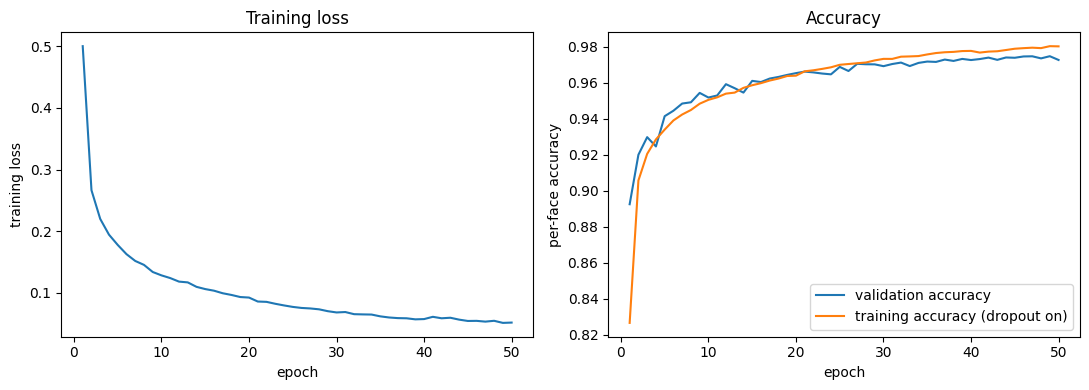

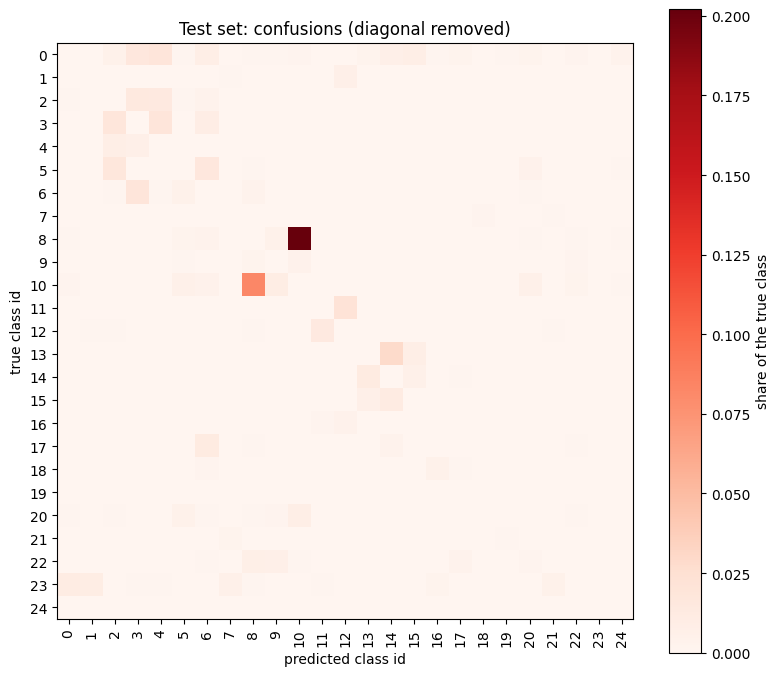

Saved: /content/drive/MyDrive/mfcad_project/results/phase5_part_stats.json
Marked done: phase5b_analysis


In [11]:
#chunk 2
#5 per part analysis and plot
# ===== PHASE 5b (CPU): per-part errors, confidence analysis, plots for the report =====
import sys, json                                       # system tools and JSON
import numpy as np                                     # array maths
import torch                                           # loading the saved files
import matplotlib.pyplot as plt                        # plotting
from google.colab import drive                         # connect to Google Drive
drive.mount('/content/drive')                          # accept the popup if it appears
PROJECT = "/content/drive/MyDrive/mfcad_project"       # our project folder
sys.path.append(PROJECT)                               # so Python can find our own files
import helpers                                         # helper tools

raw = torch.load(f"{PROJECT}/data/raw_test.pt", weights_only=False)["batches"]       # test data (labels, part boundaries)
pr = torch.load(f"{PROJECT}/results/phase5_pred_test.pt", weights_only=False)        # saved predictions

part_rows = []                                         # one entry per part: (model id, faces, wrong faces)
conf_all, ok_all = [], []                              # confidence and correctness of every face
for b, pred, conf in zip(raw, pr["pred"], pr["conf"]): # go through the batches in the same order as the predictions
    y = b["y"].long()                                  # true classes
    wrong = pred.long() != y                           # True where the model is wrong
    part = torch.searchsorted(b["face_end"].contiguous(), torch.arange(len(y)))   # part number of every face
    n_parts = len(b["model_ids"])                      # parts in this batch
    assert int(part.max()) < n_parts, "part numbering is inconsistent"   # safety check
    faces = torch.bincount(part, minlength=n_parts)    # faces per part
    n_wrong = torch.bincount(part, weights=wrong.float(), minlength=n_parts)   # wrong faces per part
    for i, mid in enumerate(b["model_ids"]):           # store one row per part
        part_rows.append((mid, int(faces[i]), int(n_wrong[i])))
    conf_all.append(conf.float())                      # confidence of each face
    ok_all.append(~wrong)                              # True where the model is right

faces = np.array([r[1] for r in part_rows])            # faces per part
wrongs = np.array([r[2] for r in part_rows])           # wrong faces per part
print("parts:", len(part_rows), "| faces:", int(faces.sum()), "| wrong faces:", int(wrongs.sum()))
print(f"parts with 0 wrong faces: {100 * (wrongs == 0).mean():.1f}%")
order = np.argsort(-wrongs)                            # parts sorted from most to fewest wrong faces
k = len(order) // 10                                   # the worst 10% of parts
print(f"worst 10% of parts hold {100 * wrongs[order[:k]].sum() / wrongs.sum():.1f}% of all wrong faces")
print("\n10 worst parts (open their STEP files in step/test/):")
for i in order[:10]:                                   # id, number of faces, number of wrong faces
    print(f"  model {part_rows[i][0]}: {part_rows[i][1]} faces, {part_rows[i][2]} wrong")

conf = torch.cat(conf_all).numpy()                     # all confidences in one list
ok = torch.cat(ok_all).numpy()                         # all correctness flags in one list
print(f"\nmean confidence: correct faces {conf[ok].mean():.3f} | wrong faces {conf[~ok].mean():.3f}")
for t in (0.5, 0.8, 0.9, 0.95, 0.99):                  # keep only faces the model is sure about
    keep = conf >= t
    print(f"confidence >= {t}: keeps {100 * keep.mean():.1f}% of faces, accuracy on those {100 * ok[keep].mean():.2f}%")

# ---- plot 1: learning curves ----
hist = json.load(open(f"{PROJECT}/results/phase3_history.json"))      # per-epoch numbers saved during training
ep = [h["epoch"] for h in hist]                        # epoch numbers
fig, ax = plt.subplots(1, 2, figsize=(11, 4))          # two panels side by side
ax[0].plot(ep, [h["train_loss"] for h in hist])        # training loss
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss"); ax[0].set_title("Training loss")
ax[1].plot(ep, [h["val_acc"] for h in hist], label="validation accuracy")             # validation accuracy
ax[1].plot(ep, [h["train_acc"] for h in hist], label="training accuracy (dropout on)") # running training accuracy
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("per-face accuracy"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{PROJECT}/results/learning_curve.png", dpi=150); plt.show()   # save to Drive and show

# ---- plot 2: where the test errors are (diagonal removed so the mistakes stand out) ----
cm = np.array(json.load(open(f"{PROJECT}/results/phase4_final.json"))["test_confusion"], dtype=float)   # test confusion matrix
rate = cm / cm.sum(1, keepdims=True)                   # share of each true class given to each predicted class
np.fill_diagonal(rate, 0)                              # remove correct predictions
plt.figure(figsize=(8, 7))
plt.imshow(rate, cmap="Reds")                          # darker = more often confused
plt.colorbar(label="share of the true class")
plt.xlabel("predicted class id"); plt.ylabel("true class id")
plt.title("Test set: confusions (diagonal removed)")
plt.xticks(range(25), rotation=90); plt.yticks(range(25))
plt.tight_layout(); plt.savefig(f"{PROJECT}/results/test_confusion_errors.png", dpi=150); plt.show()

helpers.save_json({"parts": [list(r) for r in part_rows]}, "results", "phase5_part_stats.json")   # keep the per-part table
helpers.mark_done("phase5b_analysis", note="per-part errors, confidence analysis, two report plots")

In [12]:
#chunk 3
#1
#adj version

%%writefile /content/drive/MyDrive/mfcad_project/model_adj.py
# model_adj.py - Hierarchical CADNet, ADJ version, rebuilt from the authors' public TensorFlow code
import math                                             # square roots for the initialisation
import torch                                            # PyTorch
import torch.nn as nn                                   # layer building blocks
PROJECT = "/content/drive/MyDrive/mfcad_project"        # our project folder
NUM_CLASSES = 25                                        # machining feature classes

def _tn(shape, std):                                    # trainable weight, truncated normal like TensorFlow (cut at 2 std)
    w = torch.empty(*shape)                             # empty tensor of the right shape
    nn.init.trunc_normal_(w, mean=0.0, std=std, a=-2 * std, b=2 * std)   # fill it
    return nn.Parameter(w)                              # make it trainable

class Embed(nn.Module):                                 # dense layer: x W + b
    def __init__(self, cin, cout):                      # input and output channels
        super().__init__()                              # standard setup
        self.W = _tn((cin, cout), 1.0 / math.sqrt(cin)) # authors: std 1/sqrt(inputs)
        self.b = nn.Parameter(torch.full((cout,), 0.1)) # authors: bias starts at 0.1
    def forward(self, x):                               # x = (vertices, cin)
        return x @ self.W + self.b                      # linear map

class EBlock(nn.Module):                                # embedding, batch norm, ReLU, dropout
    def __init__(self, cin, cout, rate):                # sizes and dropout rate
        super().__init__()                              # standard setup
        self.emb = Embed(cin, cout)                     # dense layer
        self.bn = nn.BatchNorm1d(cout, eps=1e-3, momentum=0.01)   # Keras defaults (momentum 0.99 -> 0.01 here)
        self.drop = nn.Dropout(rate)                    # dropout
    def forward(self, x):                               # x = (vertices, cin)
        return self.drop(torch.relu(self.bn(self.emb(x))))   # same order as the authors

class Block(nn.Module):                                 # graph convolution, batch norm, ReLU, dropout
    def __init__(self, cin, cout, rate):                # sizes and dropout rate
        super().__init__()                              # standard setup
        std = math.sqrt(1.0 / cin)                      # authors: std 1/sqrt(inputs)
        self.W = _tn((cin, cout), std)                  # weight for the neighbour sum
        self.W_I = _tn((cin, cout), std)                # weight for the vertex itself
        self.b = nn.Parameter(torch.full((cout,), 0.1)) # bias starts at 0.1
        self.bn = nn.BatchNorm1d(cout, eps=1e-3, momentum=0.01)   # batch norm
        self.drop = nn.Dropout(rate)                    # dropout
    def forward(self, x, edges):                        # edges = (row, col) with A[row, col] = 1
        row, col = edges                                # the two index lists
        agg = torch.zeros_like(x).index_add_(0, row, x[col])   # (A x): plain SUM over neighbours, no averaging
        out = agg @ self.W + x @ self.W_I + self.b      # out = (A x) W + x W_I + b
        return self.drop(torch.relu(self.bn(out)))      # batch norm, ReLU, dropout

class HierAdj(nn.Module):                               # the full network (ADJ version)
    def __init__(self, units=512, layers=6, rate=0.3):  # paper: 512 filters, 6 layers per level, dropout 0.3
        super().__init__()                              # standard setup
        self.start = EBlock(5, units, rate)             # face embedding (5 raw face features)
        self.W4 = _tn((units, 4), math.sqrt(1.0 / (units * 2)))   # transfer faces -> facets (512 x 4), no bias
        self.bn_a4 = nn.BatchNorm1d(4, eps=1e-3, momentum=0.01)   # batch norm on the 4 transferred channels
        self.facet = nn.ModuleList([Block(4 if i == 0 else units, units, rate) for i in range(layers)])   # facet convolutions
        self.emb2 = EBlock(units, units, rate)          # facet embedding
        self.W3 = _tn((units, units), math.sqrt(1.0 / (units * 2)))   # transfer facets -> faces (512 x 512), no bias
        self.bn_a3 = nn.BatchNorm1d(units, eps=1e-3, momentum=0.01)   # batch norm after that transfer
        self.face = nn.ModuleList([Block(units, units, rate) for _ in range(layers)])   # face convolutions (ONE adjacency A_1)
        self.emb1 = EBlock(units, units, rate)          # face embedding
        self.final = Embed(units, NUM_CLASSES)          # 25 class scores (softmax is inside the loss)
    def forward(self, g):                               # g = one batch graph on the GPU
        x1 = self.start(g["v1"])                        # face vectors (faces, 512)
        row3, col3 = g["a3"]                            # A_3: row = facet, col = face
        m, n = g["v2"].shape[0], g["v1"].shape[0]       # number of facets and faces
        p = x1 @ self.W4                                # project to 4 channels first (same maths as (A_3 x1) W, cheaper)
        a4 = x1.new_zeros((m, 4)).index_add_(0, row3, p[col3])   # every facet receives its face's vector
        x2 = g["v2"] + torch.relu(self.bn_a4(a4))       # add to the raw facet features (4 channels)
        for i, blk in enumerate(self.facet):            # six facet convolutions on A_2
            r = blk(x2, g["a2"])                        # one convolution block
            x2 = r if i == 0 else x2 + r                # first layer replaces, the others add (residual)
        x2 = self.emb2(x2)                              # facet embedding
        s = x1.new_zeros((n, x2.shape[1])).index_add_(0, col3, x2[row3])   # every face receives the SUM of its facets
        x1 = x1 + torch.relu(self.bn_a3(s @ self.W3))   # dense transfer, batch norm, ReLU, residual onto the faces
        for blk in self.face:                           # six face convolutions on A_1
            x1 = x1 + blk(x1, g["a1"])                  # residual connection
        x1 = self.emb1(x1)                              # face embedding
        return self.final(x1)                           # class scores per face

def count_params(model):                                # trainable weights and batch-norm statistics
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)   # trainable weights
    stats = sum(b.numel() for k, b in model.named_buffers() if not k.endswith("num_batches_tracked"))   # running mean and variance
    return train, stats                                 # the paper counts both

def load_split(split, device):                          # load raw batches and move them to the GPU
    raw = torch.load(f"{PROJECT}/data/raw_{split}.pt", weights_only=False)["batches"]   # batches in file order
    out = []                                            # result list
    for b in raw:                                       # every batch
        g = {"v1": torch.as_tensor(b["v1"]).float().to(device),   # raw face features (faces, 5)
             "v2": torch.as_tensor(b["v2"]).float().to(device),   # raw facet features (facets, 4)
             "y": torch.as_tensor(b["y"]).long().to(device)}      # true classes
        assert g["v1"].shape[1] == 5 and g["v2"].shape[1] == 4, "unexpected feature shapes"   # safety check
        for k in ("a1", "a2", "a3"):                    # face adjacency, facet adjacency, facet-face links
            a = torch.as_tensor(b[k]).long()            # (2, E) index lists
            assert a.shape[0] == 2, "adjacency must be (2, E)"   # safety check
            g[k] = (a[0].to(device), a[1].to(device))   # (row, col) on the GPU
        out.append(g)                                   # keep this batch
    del raw                                             # free CPU memory
    return out                                          # list of GPU batches

def evaluate(model, graphs):                            # accuracy, macro-F1, mean IoU, per-class IoU, confusion matrix
    model.eval()                                        # no dropout, batch norm uses running statistics
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=graphs[0]["y"].device)   # rows = true class
    with torch.no_grad():                               # no gradients needed
        for g in graphs:                                # every batch
            pred = model(g).argmax(1)                   # predicted class per face
            cm += torch.bincount(g["y"] * NUM_CLASSES + pred, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)   # add counts
    tp = cm.diag().float(); fp = cm.sum(0).float() - tp; fn = cm.sum(1).float() - tp   # per-class counts
    iou = tp / (tp + fp + fn).clamp(min=1)              # per-class IoU
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)       # per-class F1
    return (tp.sum() / cm.sum()).item(), f1.mean().item(), iou.mean().item(), iou.cpu(), cm.cpu()   # results

Writing /content/drive/MyDrive/mfcad_project/model_adj.py


In [13]:
#chunk 3
#2
import sys, importlib                                   # path tools
import torch, torch.nn.functional as F                  # PyTorch
sys.path.append("/content/drive/MyDrive/mfcad_project") # make our own files importable
import model_adj                                        # the file we just wrote
importlib.reload(model_adj)                             # pick up the newest version
m = model_adj.HierAdj()                                 # build the network
tr, st = model_adj.count_params(m)                      # count parameters
print(tr, st, tr + st, "-> expected 6599201 16392 6615593 (paper: 6.62M)")   # must match exactly
n, mf = 40, 400                                         # tiny random graph: 40 faces, 400 facets
g = {"v1": torch.rand(n, 5), "v2": torch.rand(mf, 4), "y": torch.randint(0, 25, (n,))}   # random features and labels
g["a3"] = (torch.arange(mf), torch.randint(0, n, (mf,)))   # every facet belongs to one face
e = torch.randint(0, n, (2, 120)); g["a1"] = (e[0], e[1])  # random face edges
f = torch.randint(0, mf, (2, 1200)); g["a2"] = (f[0], f[1])   # random facet edges
m.train(); out = m(g); loss = F.cross_entropy(out, g["y"]); loss.backward()   # one forward and backward pass
ok = all(p.grad is not None and torch.isfinite(p.grad).all() for p in m.parameters())   # all gradients finite?
print("output shape:", tuple(out.shape), "| loss:", round(loss.item(), 3), "| gradients finite:", ok)   # expect (40, 25), about 3.2, True

6599201 16392 6615593 -> expected 6599201 16392 6615593 (paper: 6.62M)
output shape: (40, 25) | loss: 3.299 | gradients finite: True


In [14]:
import os, sys, time, json                              # system tools
import torch, torch.nn.functional as F                  # PyTorch
from google.colab import drive                          # Drive
drive.mount('/content/drive')                           # safe to run twice
PROJECT = "/content/drive/MyDrive/mfcad_project"        # project folder
sys.path.append(PROJECT)                                # make our files importable
import helpers, model_adj                               # our helpers and the new model
assert torch.cuda.is_available(), "No GPU: run your CUDA starter cell and restart the session"   # GPU needed
DEV = "cuda"                                            # use the GPU
TARGET_EPOCHS = 40                                      # the Edge run had 50; compare at equal epochs
STOP_AFTER_MIN = 80                                     # stops cleanly after the first epoch past this many minutes
torch.manual_seed(0)                                    # fixed seed
model = model_adj.HierAdj().to(DEV)                     # the Adj network
opt = torch.optim.Adam(model.parameters(), lr=1e-2, eps=1e-7)   # authors: Adam, lr 1e-2 constant (Keras eps 1e-7)
LAST, BEST = f"{PROJECT}/models/hier_adj_last.pt", f"{PROJECT}/models/hier_adj_best.pt"   # NEW names: Edge files are untouched
start, hist, best = 0, [], 0.0                          # fresh start
if os.path.exists(LAST):                                # resume after a disconnect
    ck = torch.load(LAST, map_location=DEV, weights_only=False)   # our own checkpoint
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])   # restore weights and optimizer
    start, hist, best = ck["epoch"], ck["history"], ck["best_acc"]       # restore progress
    print("Resuming after epoch", start)                # tell the user
train_g = model_adj.load_split("train", DEV)            # all training batches on the GPU
val_g = model_adj.load_split("val", DEV)                # all validation batches on the GPU
print("train batches:", len(train_g), "| val batches:", len(val_g), "(expect 1473 and 312)")   # sanity check
try:                                                    # Edge validation curve for comparison
    edge = {h["epoch"]: h["val_acc"] for h in json.load(open(f"{PROJECT}/results/phase3_history.json"))}   # saved by the Edge run
except Exception:                                       # if the file is missing or different
    edge = {}                                           # skip the comparison column
params = [p for p in model.parameters() if p.requires_grad]   # for per-tensor gradient clipping
t_start = time.time()                                   # session clock
for epoch in range(start, TARGET_EPOCHS):               # epochs
    t0 = time.time(); model.train()                     # timer and training mode
    tot = torch.zeros((), device=DEV); cor = torch.zeros((), device=DEV); nf = 0   # running loss, correct faces, face count
    for g in train_g:                                   # ONE h5 batch per step, in file order (as the authors)
        opt.zero_grad(set_to_none=True)                 # clear gradients
        logits = model(g)                               # forward pass
        loss = F.cross_entropy(logits, g["y"])          # same as softmax + categorical cross-entropy
        loss.backward()                                 # gradients
        for p in params:                                # authors: clip EACH tensor's gradient to norm 1.0
            p.grad.mul_(torch.clamp(1.0 / (p.grad.norm() + 1e-6), max=1.0))   # scale down only if the norm is above 1
        opt.step()                                      # update weights
        k = len(g["y"]); tot += loss.detach() * k; cor += (logits.argmax(1) == g["y"]).sum(); nf += k   # statistics
    acc, f1, iou, _, _ = model_adj.evaluate(model, val_g)   # validation
    hist.append({"epoch": epoch + 1, "train_loss": (tot / nf).item(), "train_acc": (cor / nf).item(),
                 "val_acc": acc, "val_macro_f1": f1, "val_mean_iou": iou, "seconds": time.time() - t0})   # same keys as the Edge history
    if acc > best:                                      # new best validation accuracy?
        best = acc                                      # remember it
        torch.save({"model": model.state_dict(), "epoch": epoch + 1, "val_acc": acc}, BEST + ".tmp"); os.replace(BEST + ".tmp", BEST)   # save safely
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "epoch": epoch + 1, "history": hist, "best_acc": best}, LAST + ".tmp"); os.replace(LAST + ".tmp", LAST)   # resume point
    helpers.save_json(hist, "results", "adj_history.json")   # keep the curve on Drive
    e_acc = edge.get(epoch + 1)                         # Edge validation accuracy at the same epoch
    print(f"epoch {epoch+1}/{TARGET_EPOCHS} loss {hist[-1]['train_loss']:.4f} train_acc {hist[-1]['train_acc']:.4f} val_acc {acc:.4f} (Edge at this epoch: {e_acc if e_acc is None else round(e_acc, 4)}) best {best:.4f} ({time.time()-t0:.0f}s)")   # progress line
    if (time.time() - t_start) / 60 > STOP_AFTER_MIN:   # out of time budget?
        print("Time budget reached: stopped cleanly. Run this cell again later to continue."); break   # stop
if hist and hist[-1]["epoch"] >= TARGET_EPOCHS:         # finished all epochs
    helpers.mark_done("adj_train", note=f"Adj trained {TARGET_EPOCHS} epochs, best val acc {best:.4f}")   # record progress
if edge and hist:                                       # fair comparison at equal epochs
    last_ep = hist[-1]["epoch"]                         # epochs completed by Adj
    print(f"Best val acc within {last_ep} epochs: Adj {best:.4f} | Edge {max(v for k, v in edge.items() if k <= last_ep):.4f}")   # summary

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train batches: 1473 | val batches: 312 (expect 1473 and 312)
Saved: /content/drive/MyDrive/mfcad_project/results/adj_history.json
epoch 1/40 loss 0.7035 train_acc 0.7646 val_acc 0.7800 (Edge at this epoch: 0.8925) best 0.7800 (120s)
Saved: /content/drive/MyDrive/mfcad_project/results/adj_history.json
epoch 2/40 loss 0.4013 train_acc 0.8604 val_acc 0.8160 (Edge at this epoch: 0.92) best 0.8160 (122s)
Saved: /content/drive/MyDrive/mfcad_project/results/adj_history.json
epoch 3/40 loss 0.3217 train_acc 0.8863 val_acc 0.8514 (Edge at this epoch: 0.9298) best 0.8514 (121s)
Saved: /content/drive/MyDrive/mfcad_project/results/adj_history.json
epoch 4/40 loss 0.2766 train_acc 0.9005 val_acc 0.8784 (Edge at this epoch: 0.9246) best 0.8784 (121s)
Saved: /content/drive/MyDrive/mfcad_project/results/adj_history.json
epoch 5/40 loss 0.2514 train_acc 0.9085 val_acc 0.9056 

In [15]:
import os, sys, json                                    # system tools
import torch                                            # PyTorch
from google.colab import drive                          # Drive
drive.mount('/content/drive')                           # safe to run twice
PROJECT = "/content/drive/MyDrive/mfcad_project"        # project folder
sys.path.append(PROJECT)                                # make our files importable
import helpers, model_adj                               # helpers and the model
assert torch.cuda.is_available(), "No GPU: run your CUDA starter cell and restart the session"   # GPU needed
assert not os.path.exists(f"{PROJECT}/results/adj_final.json"), "TEST was already evaluated for Adj: do not run it again"   # test only once
names = ["Chamfer", "Through hole", "Triangular passage", "Rectangular passage", "6-sided passage", "Triangular through slot",
         "Rectangular through slot", "Circular through slot", "Rectangular through step", "2-sided through step",
         "Slanted through step", "O-ring", "Blind hole", "Triangular pocket", "Rectangular pocket", "6-sided pocket",
         "Circular end pocket", "Rectangular blind slot", "Vertical circular end blind slot",
         "Horizontal circular end blind slot", "Triangular blind step", "Circular blind step", "Rectangular blind step",
         "Round", "Stock"]                              # class names 0-24
model = model_adj.HierAdj().to("cuda")                  # build the network
ck = torch.load(f"{PROJECT}/models/hier_adj_best.pt", map_location="cuda", weights_only=False)   # best-validation checkpoint
model.load_state_dict(ck["model"])                      # restore weights and batch-norm statistics
print("checkpoint epoch:", ck["epoch"], "| stored val acc:", round(ck["val_acc"], 4))   # what we loaded
va, vf, vi, _, _ = model_adj.evaluate(model, model_adj.load_split("val", "cuda"))   # validation again
print(f"VAL : acc {va:.4f} | macro-F1 {vf:.4f} | mean IoU {vi:.4f}  (must match the stored value)")   # consistency check
ta, tf, ti, iou, cm = model_adj.evaluate(model, model_adj.load_split("test", "cuda"))   # THE test evaluation
print(f"TEST: acc {ta:.4f} | macro-F1 {tf:.4f} | mean IoU {ti:.4f} | faces {int(cm.sum())}")   # headline numbers
print("Edge (50 epochs): VAL 0.9748 / 0.9667 / 0.9384 | TEST 0.9739 / 0.9650 / 0.9353 | paper: Edge 97.37, Adj 96.52 (accuracy)")   # references
print("\nWeakest 6 classes on TEST (IoU):")             # section title
for c in iou.argsort()[:6].tolist():                    # the six lowest IoUs
    print(f"  {c:2d} {names[c]:36s} {iou[c]:.3f}")      # one line per class
off = cm.clone(); off.fill_diagonal_(0)                 # remove correct predictions
print("\nLargest confusions on TEST (true -> predicted):")   # section title
for flat in off.flatten().argsort(descending=True)[:6].tolist():   # six biggest mistakes
    t, p = divmod(flat, 25)                             # true and predicted class
    print(f"  {names[t]} -> {names[p]}: {int(off[t, p])} faces ({off[t, p] / cm[t].sum():.1%} of that class)")   # one line each
helpers.save_json({"epoch": ck["epoch"], "val_acc": va, "val_macro_f1": vf, "val_mean_iou": vi, "test_acc": ta, "test_macro_f1": tf,
                   "test_mean_iou": ti, "test_per_class_iou": iou.tolist(), "test_confusion": cm.tolist()}, "results", "adj_final.json")   # save
helpers.mark_done("adj_final", note="Adj evaluated on val and once on test")   # record progress

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
checkpoint epoch: 40 | stored val acc: 0.9671
VAL : acc 0.9671 | macro-F1 0.9552 | mean IoU 0.9183  (must match the stored value)
TEST: acc 0.9667 | macro-F1 0.9539 | mean IoU 0.9160 | faces 259128
Edge (50 epochs): VAL 0.9748 / 0.9667 / 0.9384 | TEST 0.9739 / 0.9650 / 0.9353 | paper: Edge 97.37, Adj 96.52 (accuracy)

Weakest 6 classes on TEST (IoU):
  10 Slanted through step                 0.675
   8 Rectangular through step             0.687
   5 Triangular through slot              0.817
   6 Rectangular through slot             0.821
   0 Chamfer                              0.838
   2 Triangular passage                   0.874

Largest confusions on TEST (true -> predicted):
  Slanted through step -> Rectangular through step: 1165 faces (17.0% of that class)
  Rectangular through step -> Slanted through step: 913 faces (13.4% of that class)
  Rectangula